# RecruitGen — Model 1 of 3: Autoencoder (Resume Image Denoising)

**Goal:** remove noise from scanned / low-quality resume images so the text becomes reliably readable.

```
Noisy Image → Encoder → Latent Space → Decoder → Denoised Resume
```

**Training concept:** input = noisy resume, target = clean resume.
**Metrics:** MSE, PSNR, SSIM, visual comparison. **Regularisation:** Early Stopping.

**Outputs:** `encoder.h5` and `decoder.h5` (used by the Streamlit app).

## 1. Setup

In [1]:
import tensorflow as tf
from tensorflow.keras import mixed_precision

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision enabled.")
else:
    print("Using default precision because no GPU was detected.")

Mixed precision enabled.


In [2]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import keras
from keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 256          # model works on 256x256 grayscale tiles
QUICK_RUN = False       # True = tiny run to test the notebook end-to-end
NUM_PAGES = 60
PATCHES_PER_PAGE = 8
EPOCHS = 1 if QUICK_RUN else 70
BATCH_SIZE = 32

DATA_DIR = "data/clean_resumes"   # optional: put your own clean resume images here
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.13.2


## 2. Dataset — clean resume pages + synthetic noise

If `data/clean_resumes/` contains clean resume/document images they are used directly.
Otherwise realistic resume-like pages are rendered (name, headings, bullet points, two-column blocks).
Noisy versions are created with gaussian noise, salt & pepper, coffee stains, blur and scan shadows.

In [3]:
WORDS = ("python java sql tensorflow pytorch aws azure docker kubernetes data analysis machine learning "
         "communication leadership project management engineer developer analyst cloud deployment "
         "university bachelor master certification experience responsible designed implemented improved "
         "pipeline dashboard model accuracy customers team agile api backend frontend testing").split()
HEADINGS = ["PROFESSIONAL SUMMARY", "EXPERIENCE", "EDUCATION", "SKILLS", "PROJECTS", "CERTIFICATIONS"]

def _font(size):
    for name in ["arial.ttf", "DejaVuSans.ttf", "LiberationSans-Regular.ttf"]:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            continue
    return ImageFont.load_default()

def render_resume_page(w=1240, h=1754):
    img = Image.new("L", (w, h), 255)
    d = ImageDraw.Draw(img)
    y = 70
    d.text((80, y), " ".join(random.sample(WORDS, 2)).upper(), fill=0, font=_font(54)); y += 80
    d.text((80, y), " | ".join(random.sample(WORDS, 3)), fill=60, font=_font(24)); y += 60
    while y < h - 120:
        d.text((80, y), random.choice(HEADINGS), fill=0, font=_font(30)); y += 44
        d.line((80, y, w - 80, y), fill=90, width=2); y += 16
        for _ in range(random.randint(3, 7)):
            line = " ".join(random.choices(WORDS, k=random.randint(6, 12))).capitalize()
            d.text((100, y), "• " + line, fill=20, font=_font(random.choice([20, 22, 24]))); y += 34
        y += 24
    return img

def add_scan_noise(img):
    arr = np.asarray(img, dtype=np.float32) / 255.0
    h, w = arr.shape
    noisy = arr + np.random.normal(0, random.uniform(0.04, 0.15), arr.shape)
    m = np.random.rand(h, w)
    sp = random.uniform(0.005, 0.03)
    noisy[m < sp / 2] = 0.0
    noisy[m > 1 - sp / 2] = 1.0
    yy, xx = np.mgrid[0:h, 0:w]
    for _ in range(random.randint(1, 4)):          # stains
        cy, cx, r = random.randint(0, h), random.randint(0, w), random.randint(40, 260)
        noisy -= np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * r ** 2)) * random.uniform(0.1, 0.35)
    noisy -= np.linspace(0, random.uniform(0, 0.25), w)[None, :]   # scan shadow
    out = Image.fromarray((np.clip(noisy, 0, 1) * 255).astype(np.uint8))
    if random.random() < 0.4:
        out = out.filter(ImageFilter.GaussianBlur(random.uniform(0.4, 1.0)))
    return out

def load_clean_pages():
    files = sorted(glob.glob(os.path.join(DATA_DIR, "*.*")))
    if files:
        print(f"Using {len(files)} clean images from {DATA_DIR}")
        return [Image.open(f).convert("L") for f in files]
    print(f"Rendering {NUM_PAGES} synthetic resume pages")
    return [render_resume_page() for _ in range(NUM_PAGES)]

def make_patches(pages):
    X, Y = [], []
    for page in pages:
        noisy = add_scan_noise(page)
        c, n = np.asarray(page, np.float32) / 255.0, np.asarray(noisy, np.float32) / 255.0
        h, w = c.shape
        for _ in range(PATCHES_PER_PAGE):
            y, x = random.randint(0, h - IMG_SIZE), random.randint(0, w - IMG_SIZE)
            X.append(n[y:y + IMG_SIZE, x:x + IMG_SIZE]); Y.append(c[y:y + IMG_SIZE, x:x + IMG_SIZE])
    return np.array(X)[..., None], np.array(Y)[..., None]

pages = load_clean_pages()
X, Y = make_patches(pages)
idx = np.random.permutation(len(X))
X, Y = X[idx], Y[idx]
n_val, n_test = int(0.15 * len(X)), int(0.10 * len(X))
X_test, Y_test = X[:n_test], Y[:n_test]
X_val, Y_val = X[n_test:n_test + n_val], Y[n_test:n_test + n_val]
X_train, Y_train = X[n_test + n_val:], Y[n_test + n_val:]
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

Rendering 60 synthetic resume pages
train (360, 256, 256, 1) | val (72, 256, 256, 1) | test (48, 256, 256, 1)


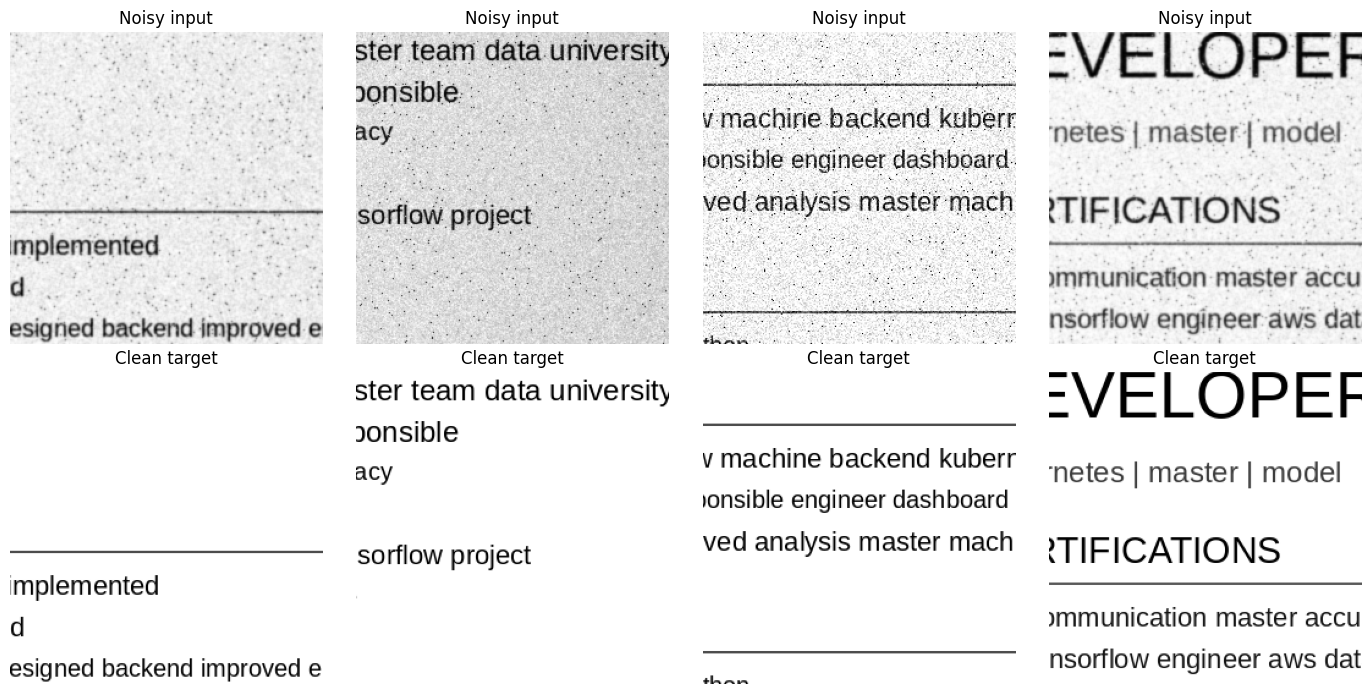

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    ax[0, i].imshow(X_train[i, ..., 0], cmap="gray"); ax[0, i].set_title("Noisy input"); ax[0, i].axis("off")
    ax[1, i].imshow(Y_train[i, ..., 0], cmap="gray"); ax[1, i].set_title("Clean target"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

## 3. Model — convolutional Encoder → Latent Space → Decoder

U-Net style autoencoder: the encoder compresses the 256×256 tile into a **32×32×256 latent space**;
the decoder reconstructs the clean tile. Skip connections keep thin text strokes sharp.

In [5]:
def conv(x, filters, name):
    return layers.Conv2D(filters, 3, padding="same", activation="relu", name=name)(x)

inp = keras.Input((IMG_SIZE, IMG_SIZE, 1), name="dirty_resume")
# ---------------- Encoder ----------------
e1 = conv(conv(inp, 32, "enc1_a"), 32, "enc1_b")                       # 256x256x32
e2 = conv(conv(layers.MaxPooling2D(name="pool1")(e1), 64, "enc2_a"), 64, "enc2_b")    # 128x128x64
e3 = conv(conv(layers.MaxPooling2D(name="pool2")(e2), 128, "enc3_a"), 128, "enc3_b")  # 64x64x128
latent = conv(layers.MaxPooling2D(name="pool3")(e3), 256, "latent_representation")  # 32x32x256
# ---------------- Decoder ----------------
d = conv(latent, 256, "dec_bottleneck")
d = layers.UpSampling2D(name="up1")(d); d = layers.Concatenate(name="skip1")([d, e3])
d = conv(conv(d, 128, "dec1_a"), 128, "dec1_b")
d = layers.UpSampling2D(name="up2")(d); d = layers.Concatenate(name="skip2")([d, e2])
d = conv(conv(d, 64, "dec2_a"), 64, "dec2_b")
d = layers.UpSampling2D(name="up3")(d); d = layers.Concatenate(name="skip3")([d, e1])
d = conv(conv(d, 32, "dec3_a"), 32, "dec3_b")
out = layers.Conv2D(1, 3, padding="same",activation="sigmoid",dtype="float32",name="clean_resume")(d)

autoencoder = keras.Model(inp, out, name="Resume_Denoising_Autoencoder")

def psnr_metric(y_true, y_pred):
    return tf.reduce_mean(tf.image.psnr(y_true, y_pred, max_val=1.0))

def ssim_metric(y_true, y_pred):
    return tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))

autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001), loss="mse",metrics=[psnr_metric, ssim_metric])
autoencoder.summary()

Model: "Resume_Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dirty_resume        │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_a (Conv2D)     │ (None, 256, 256,  │        320 │ dirty_resume[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_b (Conv2D)     │ (None, 256, 256,  │      9,248 │ enc1_a[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 128, 128,  │          0 │ enc1_b[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_a (Conv2D)     │ (None, 128, 128,  │     18,496 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_b (Conv2D)     │ (None, 128, 128,  │     36,928 │ enc2_a[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 64, 64,    │          0 │ enc2_b[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_a (Conv2D)     │ (None, 64, 64,    │     73,856 │ pool2[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_b (Conv2D)     │ (None, 64, 64,    │    147,584 │ enc3_a[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 32, 32,    │          0 │ enc3_b[0][0]      │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_representat… │ (None, 32, 32,    │    295,168 │ pool3[0][0]       │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_bottleneck      │ (None, 32, 32,    │    590,080 │ latent_represent… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up1 (UpSampling2D)  │ (None, 64, 64,    │          0 │ dec_bottleneck[0… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip1 (Concatenate) │ (None, 64, 64,    │          0 │ up1[0][0],        │
│                     │ 384)              │            │ enc3_b[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_a (Conv2D)     │ (None, 64, 64,    │    442,496 │ skip1[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec1_b (Conv2D)     │ (None, 64, 64,    │    147,584 │ dec1_a[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up2 (UpSampling2D)  │ (None, 128, 128,  │          0 │ dec1_b[0][0]    

 Total params: 1,946,561 (7.43 MB)

 Trainable params: 1,946,561 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training (with Early Stopping)

In [6]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("GPU is available!")
else:
    print("No GPU detected. Training may be running on CPU.")

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is available!


In [7]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=3,
        factor=0.5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "ae_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]
history = autoencoder.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=70,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/70
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.2125 - psnr_metric: 6.7513 - ssim_metric: 0.5610   
Epoch 1: val_loss improved from None to 0.10811, saving model to outputs/ae_best.keras

Epoch 1: finished saving model to outputs/ae_best.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 95s 4s/step - loss: 0.1962 - psnr_metric: 7.2215 - ssim_metric: 0.5754 - val_loss: 0.1081 - val_psnr_metric: 9.6407 - val_ssim_metric: 0.6164 - learning_rate: 1.0000e-04
Epoch 2/70
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - loss: 0.0733 - psnr_metric: 11.8043 - ssim_metric: 0.6524
Epoch 2: val_loss improved from 0.10811 to 0.05267, saving model to outputs/ae_best.keras

Epoch 2: finished saving model to outputs/ae_best.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 225ms/step - loss: 0.0588 - psnr_metric: 12.8761 - ssim_metric: 0.6634 - val_loss: 0.0527 - val_psnr_metric: 13.5849 - val_ssim_metric: 0.6615 - learning_rate: 1.0000e-04
Epoch 3/70
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - loss: 0.0487 - psnr_metric: 13.914

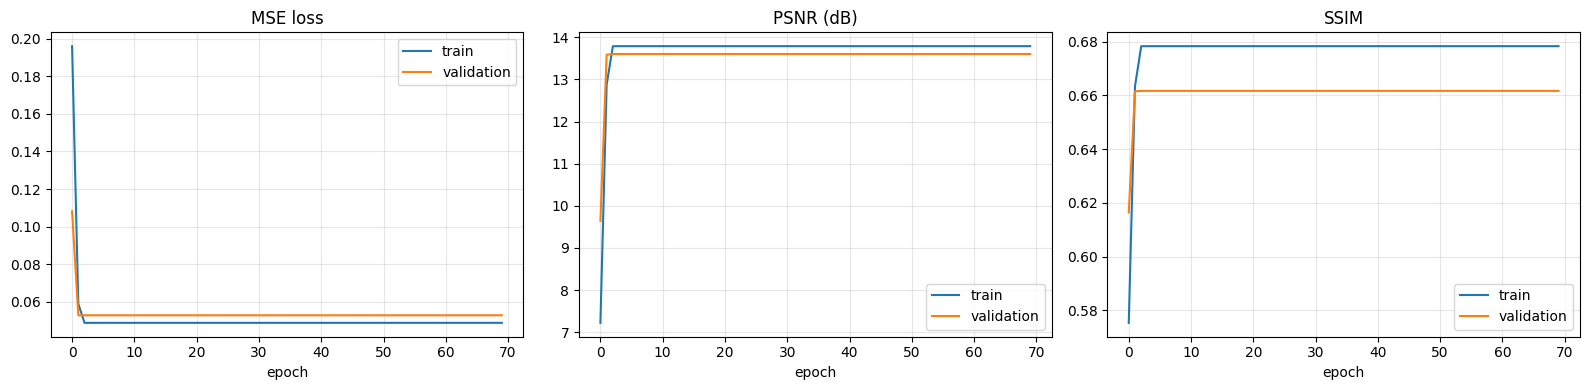

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, key, title in zip(ax, ["loss", "psnr_metric", "ssim_metric"], ["MSE loss", "PSNR (dB)", "SSIM"]):
    a.plot(history.history[key], label="train"); a.plot(history.history["val_" + key], label="validation")
    a.set_title(title); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Evaluation — MSE · PSNR · SSIM on the test set

In [9]:
pred = autoencoder.predict(X_test, batch_size=BATCH_SIZE, verbose=0)

def report(name, a, b):
    mse = float(np.mean((a - b) ** 2))
    psnr = float(tf.reduce_mean(tf.image.psnr(a, b, 1.0)))
    ssim = float(tf.reduce_mean(tf.image.ssim(a, b, 1.0)))
    print(f"{name:22s} MSE={mse:.5f}  PSNR={psnr:6.2f} dB  SSIM={ssim:.4f}")

report("Noisy vs clean", X_test, Y_test)
report("Denoised vs clean", pred, Y_test)

Noisy vs clean         MSE=0.02777  PSNR= 16.58 dB  SSIM=0.4490
Denoised vs clean      MSE=0.05144  PSNR= 13.38 dB  SSIM=0.6663


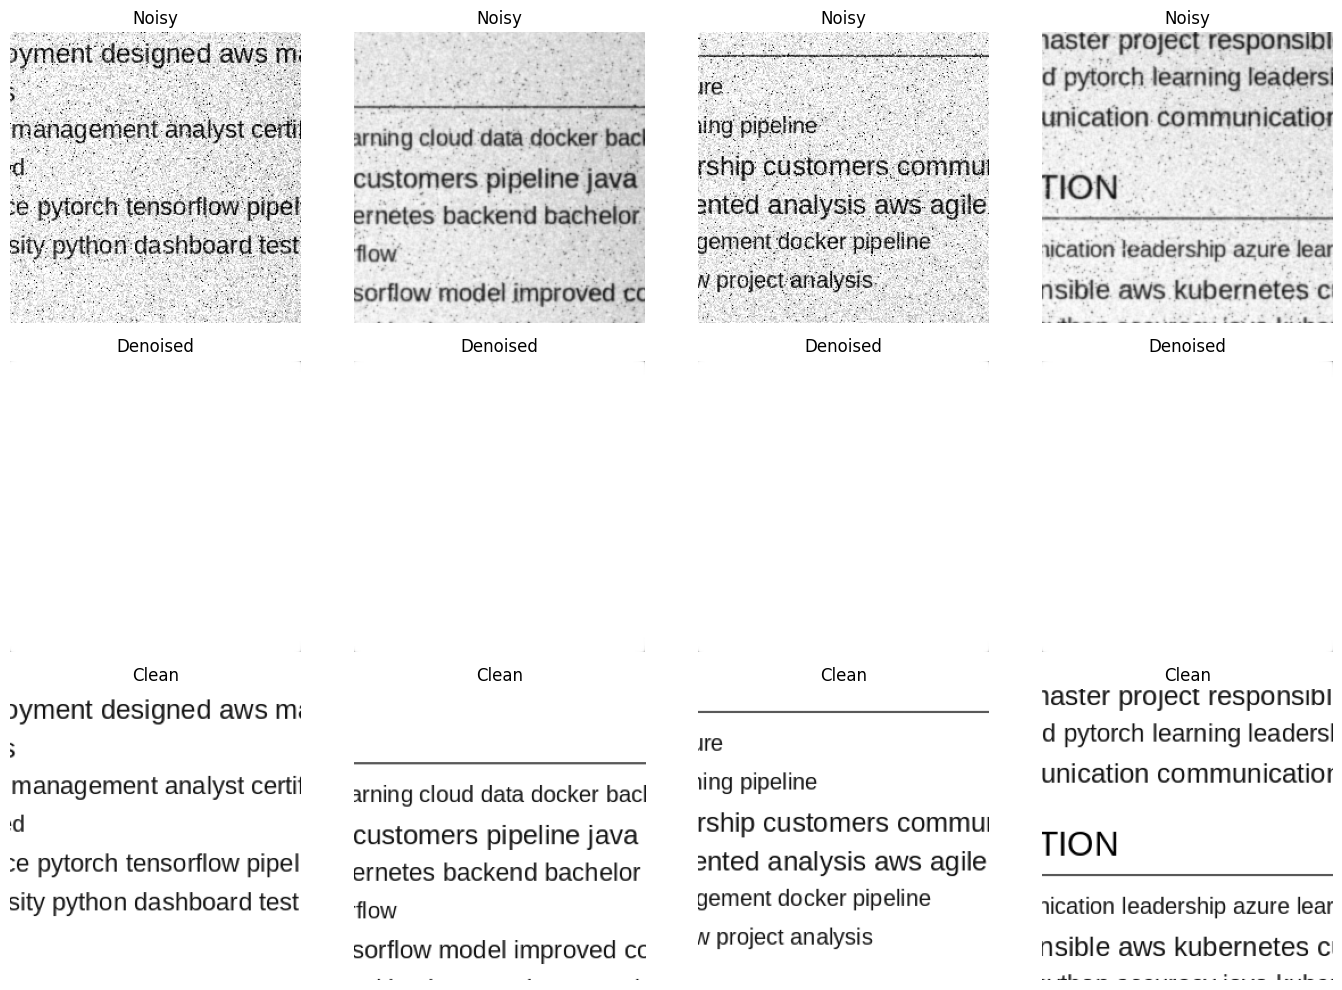

In [10]:
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for i in range(4):
    for r, (img, t) in enumerate([(X_test[i], "Noisy"), (pred[i], "Denoised"), (Y_test[i], "Clean")]):
        ax[r, i].imshow(img[..., 0], cmap="gray", vmin=0, vmax=1); ax[r, i].set_title(t); ax[r, i].axis("off")
plt.tight_layout(); plt.show()

## 6. Export — `encoder.h5` + `decoder.h5`

The encoder outputs the latent space plus the three skip feature maps; the decoder consumes them.
`decoder(encoder(x))` is identical to the full autoencoder.

In [11]:
g = autoencoder.get_layer
encoder = keras.Model(inp, [latent, e3, e2, e1], name="resume_encoder")

lat_in = keras.Input((32, 32, 256), name="latent")
s3 = keras.Input((64, 64, 128), name="skip_64")
s2 = keras.Input((128, 128, 64), name="skip_128")
s1 = keras.Input((256, 256, 32), name="skip_256")
x = g("dec_bottleneck")(lat_in)
x = g("skip1")([g("up1")(x), s3]); x = g("dec1_b")(g("dec1_a")(x))
x = g("skip2")([g("up2")(x), s2]); x = g("dec2_b")(g("dec2_a")(x))
x = g("skip3")([g("up3")(x), s1]); x = g("dec3_b")(g("dec3_a")(x))
decoder = keras.Model([lat_in, s3, s2, s1], g("clean_resume")(x), name="resume_decoder")

encoder.save(os.path.join(OUTPUT_DIR, "encoder.h5"))
decoder.save(os.path.join(OUTPUT_DIR, "decoder.h5"))

check = decoder.predict(encoder.predict(X_test[:2], verbose=0), verbose=0)
print("max |decoder(encoder(x)) - autoencoder(x)| =", float(np.abs(check - autoencoder.predict(X_test[:2], verbose=0)).max()))
print("Saved:", os.listdir(OUTPUT_DIR))

max |decoder(encoder(x)) - autoencoder(x)| = 0.0
Saved: ['decoder.h5', 'ae_best.keras', 'encoder.h5']


7. Training & Validation Loss Graph

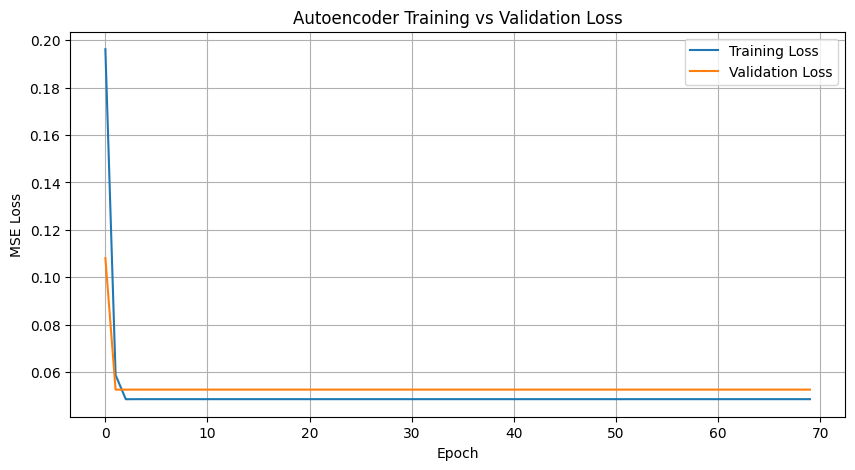

Final Training Loss: 0.04864931479096413
Final Validation Loss: 0.0526764839887619


In [12]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

print("Final Training Loss:", history.history["loss"][-1])
print("Final Validation Loss:", history.history["val_loss"][-1])

8. Reconstruction Scores

In [13]:
import numpy as np
import pandas as pd
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Generate reconstructed images
X_pred = autoencoder.predict(X_val, verbose=1)

# Convert arrays to NumPy
X_true = np.asarray(Y_val)
X_pred = np.asarray(X_pred)

# Ensure values are in the expected range
X_true = np.clip(X_true, 0, 1)
X_pred = np.clip(X_pred, 0, 1)

# Calculate metrics
mse_scores = np.mean(
    (X_true - X_pred) ** 2,
    axis=tuple(range(1, X_true.ndim))
)

mae_scores = np.mean(
    np.abs(X_true - X_pred),
    axis=tuple(range(1, X_true.ndim))
)

psnr_scores = []
ssim_scores = []

for i in range(len(X_true)):
    true_img = X_true[i]
    pred_img = X_pred[i]

    psnr_scores.append(
        peak_signal_noise_ratio(
            true_img,
            pred_img,
            data_range=1.0
        )
    )

    # Support grayscale and RGB images
    if true_img.ndim == 3 and true_img.shape[-1] == 1:
        true_img = true_img.squeeze(-1)
        pred_img = pred_img.squeeze(-1)
        channel_axis = None
    elif true_img.ndim == 3:
        channel_axis = -1
    else:
        channel_axis = None

    ssim_scores.append(
        structural_similarity(
            true_img,
            pred_img,
            data_range=1.0,
            channel_axis=channel_axis
        )
    )

# Display average scores
scores_df = pd.DataFrame({
    "Metric": ["MSE", "MAE", "PSNR (dB)", "SSIM"],
    "Average Score": [
        np.mean(mse_scores),
        np.mean(mae_scores),
        np.mean(psnr_scores),
        np.mean(ssim_scores)
    ]
})

print("Autoencoder Evaluation Scores")
display(scores_df)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 750ms/step
Autoencoder Evaluation Scores


,Metric,Average Score
0,MSE,0.052676
1,MAE,0.069726
2,PSNR (dB),13.605212
3,SSIM,0.687679


9. Original, Noisy, and Reconstructed Images

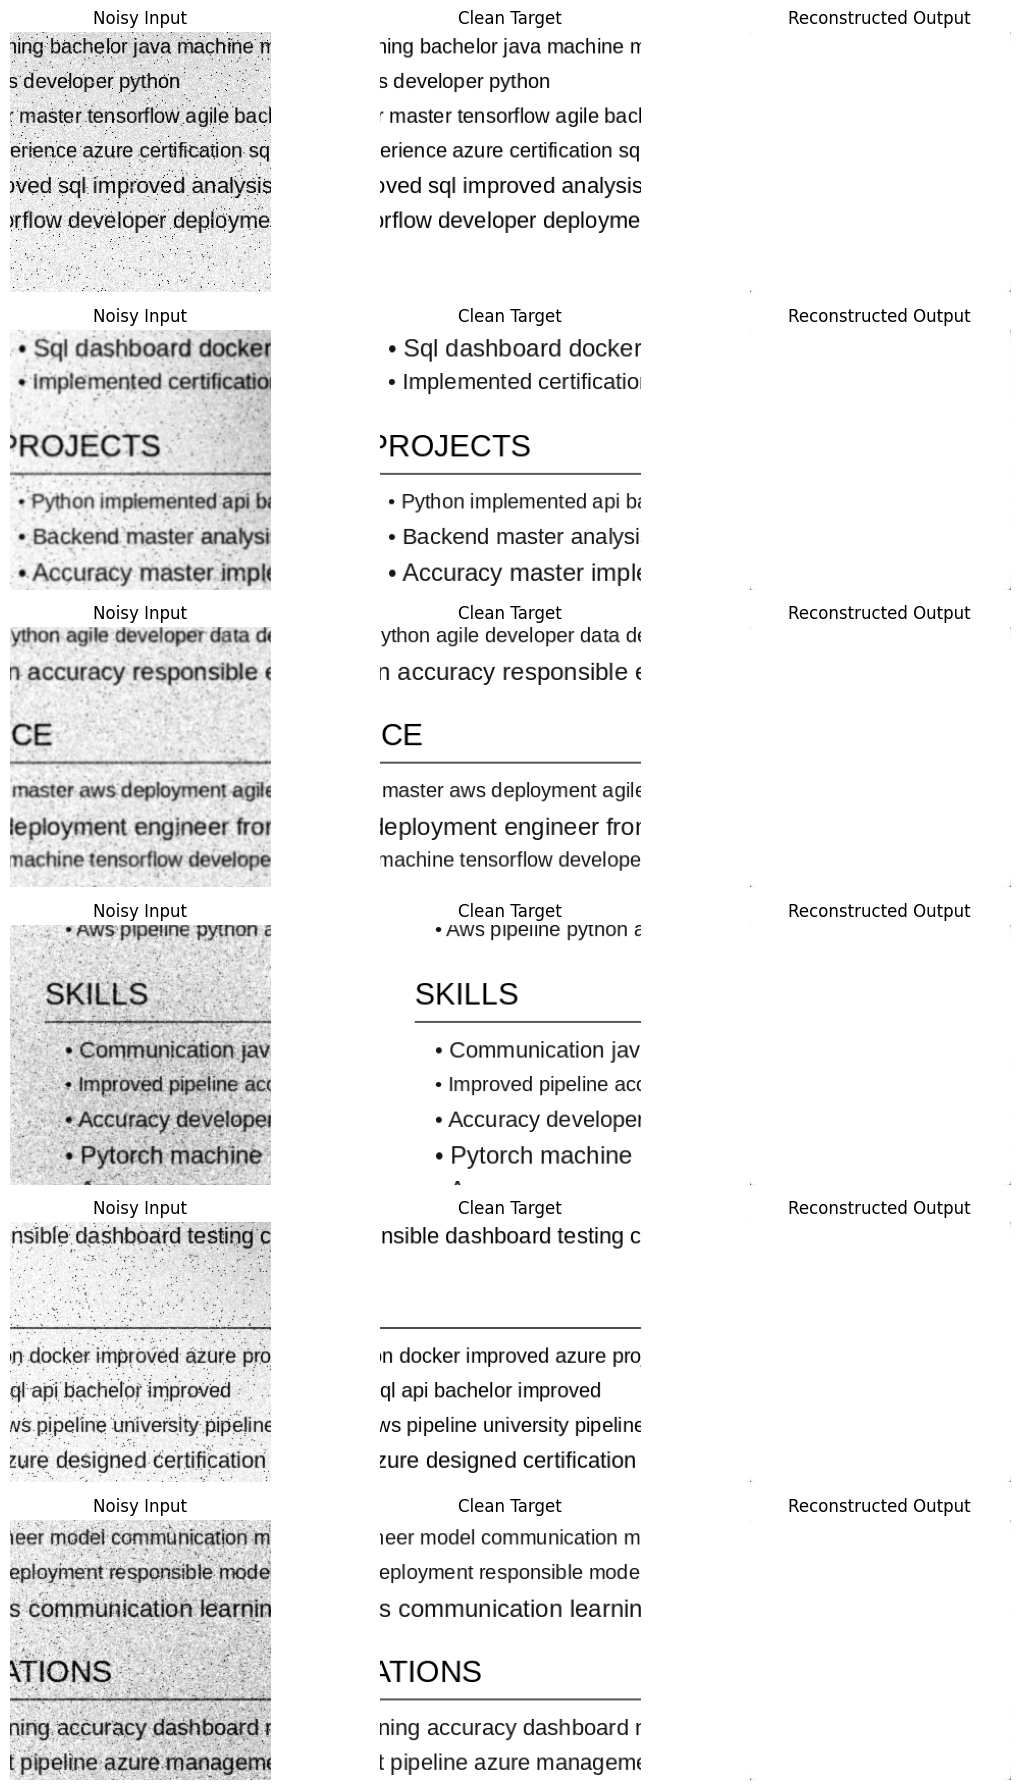

In [14]:
import matplotlib.pyplot as plt
import numpy as np

n = min(6, len(X_val))

fig, axes = plt.subplots(n, 3, figsize=(12, 3 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    images = [
        X_val[i],
        Y_val[i],
        X_pred[i]
    ]

    titles = [
        "Noisy Input",
        "Clean Target",
        "Reconstructed Output"
    ]

    for j, (img, title) in enumerate(zip(images, titles)):
        if img.ndim == 3 and img.shape[-1] == 1:
            img = img.squeeze(-1)
            axes[i, j].imshow(img, cmap="gray")
        elif img.ndim == 2:
            axes[i, j].imshow(img, cmap="gray")
        else:
            axes[i, j].imshow(img)

        axes[i, j].set_title(title)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()